Import modules

In [87]:
import pandas as pd
import matplotlib.pyplot as plt

data= pd.read_csv("./student_exam_performance.csv")
data.dropna(inplace=True)
data


,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,...,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,...,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,...,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
7,STU_000008,20,Female,Undergraduate,Private,Lower-Middle,Bachelor,Suburban,90.79,3.63,...,Easy,7,94,91,88.08,10.00,97.61,A,Pass,High
8,STU_000009,15,Male,Undergraduate,Public,Lower-Middle,Associate,Suburban,61.28,2.43,...,Hard,14,94,35,70.21,8.34,34.44,F,Fail,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99991,STU_099992,19,Female,Undergraduate,Public,Upper-Middle,Master,Suburban,72.32,3.05,...,Medium,3,97,63,75.44,7.32,61.12,D,Pass,Medium
99992,STU_099993,19,Female,High School,Public,Low,High School,Urban,67.13,2.37,...,Easy,29,94,65,98.67,10.00,67.74,C,Pass,Medium
99994,STU_099995,15,Male,High School,Public,Low,Associate,Urban,54.37,2.13,...,Easy,5,97,39,79.83,10.00,40.70,F,Fail,Low
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,...,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium


Encoding the data

In [88]:
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder

# categories=(X_train.select_dtypes(include=['object','category']).columns)
# for col in categories:
#     print(col,":", data[col].unique()[:10])

columns_for_ordinal=['education_level','family_income','parent_education',
                    'class_participation',
                     "study_consistency",
                     'study_environment',
                     'revision_frequency',
                     'notes_quality',
                     'sleep_quality',
                     'break_frequency',
                     "motivation_level",
                     'educational_app_usage',
                     'exam_difficulty'
                    ]
encoder=OrdinalEncoder(
    categories = [
        ['High School', 'Undergraduate'],
        ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
        ['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate'],
        ['Low', 'Medium', 'High'],
        ['Low', 'Medium', 'High'],
        ['Quiet', 'Moderate', 'Noisy'],
        ['Rarely', 'Weekly', 'Daily'],
        ['Poor', 'Average', 'Excellent'],
        ['Poor', 'Fair', 'Good', 'Excellent'],
        ['Rarely', 'Occasionally', 'Frequently'],
        ['Low', 'Medium', 'High'],
        ['Low', 'Moderate', 'High'],
        ['Easy', 'Medium', 'Hard']
    ]
)
data[columns_for_ordinal]=encoder.fit_transform(data[columns_for_ordinal])

columns_for_onehot= [
    "gender",
    'school_type',
    'urban_rural',
    'study_method',
    'device_availability'
]
one_hot_encoder=OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)
encoded_values= one_hot_encoder.fit_transform(data[columns_for_onehot])
new_cols= one_hot_encoder.get_feature_names_out(columns_for_onehot)
df_encoded=pd.DataFrame(encoded_values,columns=new_cols,index=data.index)
data_final=pd.concat(
    [data.drop(columns=columns_for_onehot),df_encoded],
    axis=1
)
data_final=data_final.drop('student_id',axis=1)

Splitting the data

In [110]:
from sklearn.model_selection import train_test_split
X=data_final.drop(['exam_score',"performance_grade","pass_status","performance_level"],axis=1)
y=data_final['exam_score']

X_train,x_test,y_train,y_test= train_test_split(X,y,test_size=0.2)

Traing regression model

In [112]:
from sklearn.ensemble import RandomForestRegressor

reg= RandomForestRegressor()
reg.fit(X_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [115]:
reg.score(x_test,y_test)

0.9885263221408461

In [134]:
from sklearn.metrics import mean_absolute_error,r2_score

y_pred=reg.predict(x_test)
r2= r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)

lr_results=pd.DataFrame(["Random Forest",mae,r2]).transpose()
lr_results.columns=["method",'mae','r2']
lr_results

,method,mae,r2
0,Random Forest,1.350192,0.988526


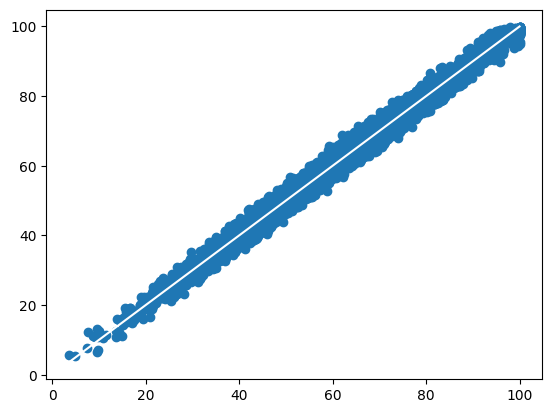

In [136]:
plt.scatter(y_test,y_pred,)
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],c="white")

Training classification model

In [160]:
from sklearn.tree import DecisionTreeClassifier

X_classification=data_final.drop(["performance_grade","pass_status","performance_level"],axis=1)
y_classification=data_final[["performance_grade","pass_status","performance_level"]]
X_train_classification,X_test_classification,y_train_clf,y_test_clf=train_test_split(X_classification,y_classification,test_size=0.2)

clf=DecisionTreeClassifier()
clf.fit(X_train_classification,y_train_clf)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [202]:
# clf.score(X_test_classification,y_test)
from sklearn.metrics import accuracy_score

y_pred_clf=clf.predict(X_test_classification)
for i,col in enumerate(y_test_clf.columns):
    score=accuracy_score(y_test_clf.iloc[:,1],y_pred_clf[:,1])
    print(col,score)

performance_grade 1.0
pass_status 1.0
performance_level 1.0
